LOAD DATA & INITIAL DATA INSPECTION

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv('Telco-Customer-Churn.csv')

# 2. Cek Struktur Data
print(df.info())
print("\nUkuran Data:", df.shape)
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


DATA CLEANSING & VALIDATION

In [2]:
# Cek missing values
print(df.isnull().sum())

# Konversi kolom numerik yang terbaca string (TotalCharges)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


/tmp/ipykernel_2614/2624762790.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [3]:
# Cek duplikat
print("Jumlah duplikat:", df.duplicated().sum())

# Pastikan kolom target (Churn) konsisten
df['Churn_Numeric'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

Jumlah duplikat: 0


EXPLORATORY DATA ANALYSIS (EDA) & VISUALISASI

Analisis Baseline Churn Rate

/tmp/ipykernel_2614/3055948152.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


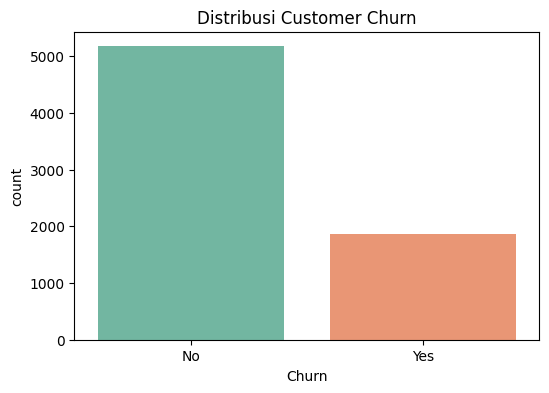

Churn Rate (%): 26.536987079369588


In [4]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Distribusi Customer Churn')
plt.show()

print("Churn Rate (%):", df['Churn_Numeric'].mean() * 100)

Analisis Variabel Kunci vs Churn

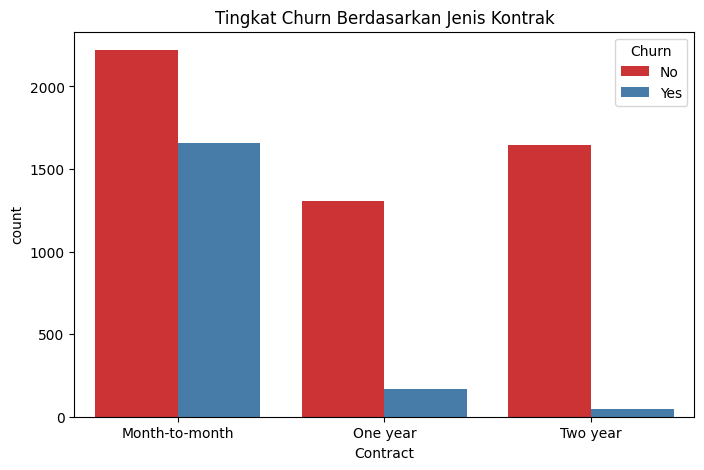

In [5]:
# plot Kontrak vs Churn
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1')
plt.title('Tingkat Churn Berdasarkan Jenis Kontrak')
plt.show()

**Analisis Jenis Kontrak (Contract vs Churn)**

Temuan: Pelanggan dengan tipe kontrak bulanan (Month-to-month) mendominasi angka churn secara masif dibandingkan pelanggan berbayar kontrak 1 tahun atau 2 tahun. Sebaliknya, pelanggan dengan kontrak Two year sangat sedikit yang melakukan churn.

Interpretasi: Fleksibilitas tanpa komitmen jangka panjang membuat pelanggan sangat mudah untuk berhenti berlangganan kapan saja.

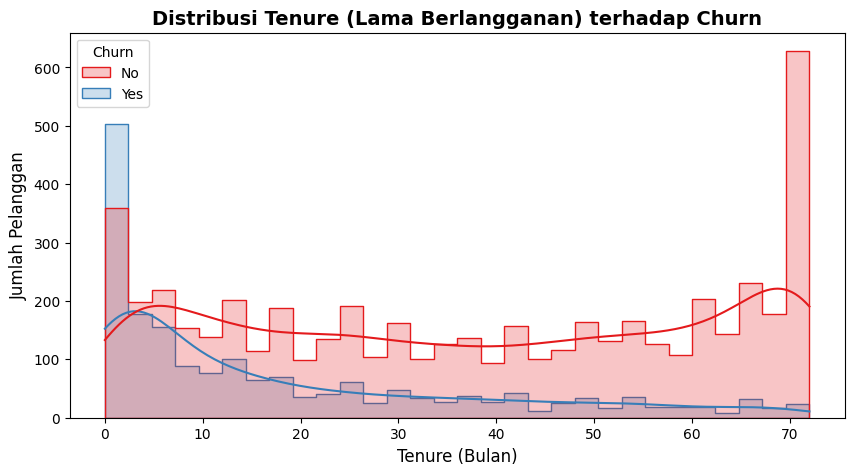

In [7]:
#Tenure vs Churn

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    kde=True,
    bins=30,
    palette='Set1',
    element='step',
    common_norm=False
)
plt.title('Distribusi Tenure (Lama Berlangganan) terhadap Churn', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Bulan)', fontsize=12)
plt.ylabel('Jumlah Pelanggan', fontsize=12)
plt.show()

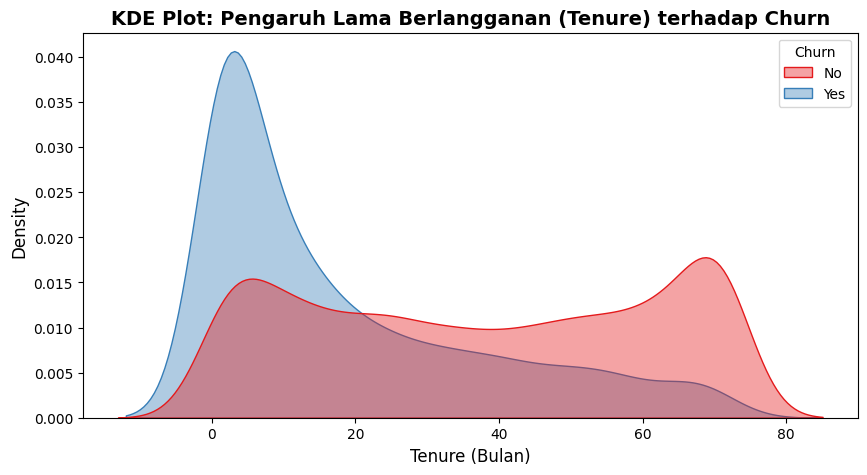

In [8]:
#alternatif tenure vs churn
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=df,
    x='tenure',
    hue='Churn',
    fill=True,
    common_norm=False,
    palette='Set1',
    alpha=0.4
)
plt.title('KDE Plot: Pengaruh Lama Berlangganan (Tenure) terhadap Churn', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Bulan)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.show()

**Analisis Masa Berlanggan (Tenure vs Churn)**

Temuan: Berdasarkan histogram dan KDE plot, puncak tertinggi pelanggan yang melakukan churn berada pada kelompok tenure awal (bulan-bulan pertama / 0–5 bulan). Sementara itu, pelanggan yang bertahan (No Churn) memiliki lonjakan signifikan pada tenure tinggi (mendekati 72 bulan / loyal).

Interpretasi: Risiko terbesar hilangnya pelanggan terjadi di awal masa berlangganan (fasa onboarding). Jika pelanggan berhasil melewati tahun pertama, loyalitas mereka akan meningkat drastis.

/tmp/ipykernel_2614/1105926688.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


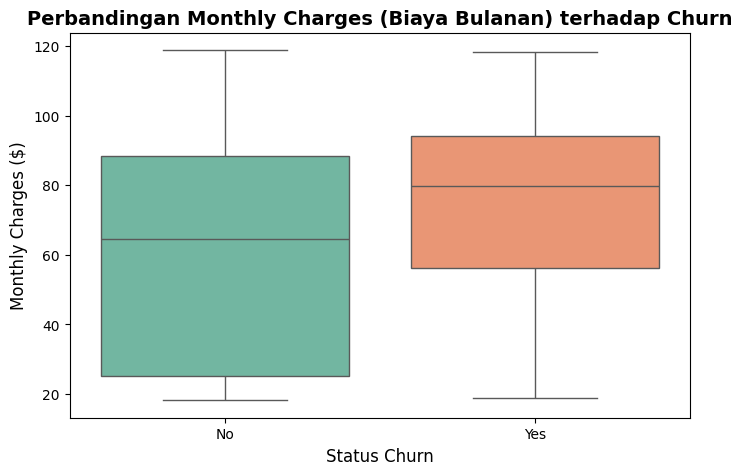

In [9]:
#Monthly Charges VS CHURN
# Menggunakan Boxplot untuk melihat perbandingan median & quartil biaya bulanan
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    palette='Set2'
)
plt.title('Perbandingan Monthly Charges (Biaya Bulanan) terhadap Churn', fontsize=14, fontweight='bold')
plt.xlabel('Status Churn', fontsize=12)
plt.ylabel('Monthly Charges ($)', fontsize=12)
plt.show()

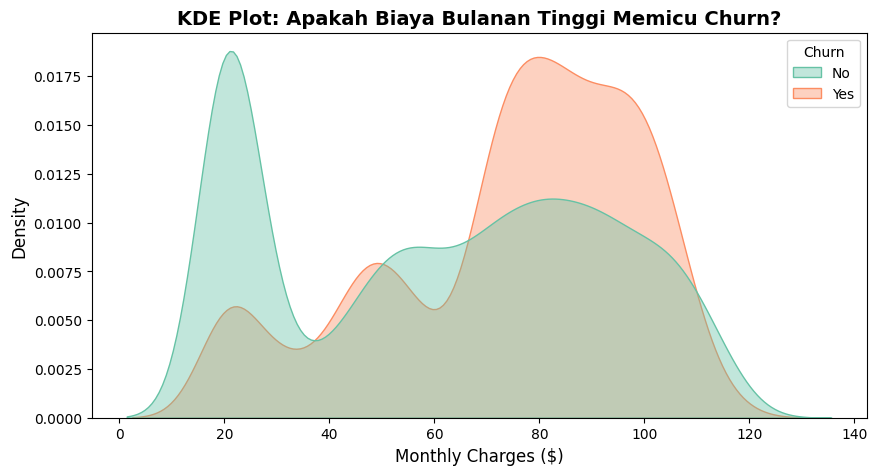

In [10]:
# Menggunakan KDE Plot untuk melihat kepadatan/distribusi harga bulanan
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=df,
    x='MonthlyCharges',
    hue='Churn',
    fill=True,
    common_norm=False,
    palette='Set2',
    alpha=0.4
)
plt.title('KDE Plot: Apakah Biaya Bulanan Tinggi Memicu Churn?', fontsize=14, fontweight='bold')
plt.xlabel('Monthly Charges ($)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.show()

**Analisis Biaya Bulanan (Monthly Charges vs Churn)**

Temuan: Dari boxplot dan KDE plot, pelanggan yang melakukan churn (Yes) memiliki nilai median dan distribusi yang terkonsentrasi di kisaran biaya bulanan yang lebih tinggi (rata-rata di atas $80–$90) dibandingkan pelanggan yang tidak churn.

Interpretasi: Harga atau biaya bulanan yang tinggi terindikasi menjadi salah satu pemicu utama pelanggan meninggalkan layanan, terutama jika mereka merasa value (nilai layanan) yang didapatkan tidak sebanding dengan harga yang dibayar.

**Rekomendasi**

1. Optimalisasi Fasa Onboarding & Retensi Dini:
Karena churn paling tinggi terjadi di awal masa langganan (low tenure), perusahaan perlu menghadirkan program khusus bagi pelanggan baru (seperti pendampingan customer success, edukasi penggunaan fitur, atau diskon khusus di bulan ke-3) untuk mengunci loyalitas sejak dini.
2. Strategi Konversi Kontrak Jangka Panjang:
Berikan insentif yang menarik (seperti potongan harga atau benefit eksklusif) bagi pengguna Month-to-month agar mereka mau beralih ke paket One year atau Two year, sehingga revenue retention perusahaan lebih stabil.
3. Evaluasi Struktur Harga & Value Bundling:
Untuk pelanggan di kelompok Monthly Charges tinggi yang rentan churn, perusahaan dapat menawarkan paket bundling layanan atau penyesuaian tier paket agar pelanggan merasa mendapatkan nilai (value for money) yang sepadan dengan pengeluaran mereka.